# Week 2: Real-World Classification Project
## SMS Spam Detection with Scikit-learn

**Project:** Classify SMS messages as `ham` (legitimate) or `spam` (unwanted).

### Objectives
- Work with a real-world, imbalanced text dataset.
- Explore message labels and message lengths.
- Create a stratified train/test split.
- Build text-classification pipelines using TF-IDF.
- Train and compare Multinomial Naive Bayes and Logistic Regression.
- Evaluate precision, recall, and F1-score for the spam class.
- Inspect confusion matrices, precision-recall curves, and informative words.

**Why F1-score matters:** Spam is the minority class. Accuracy alone can look high even if a model misses many spam messages. Precision, recall, and F1-score provide a more informative view of minority-class performance.

**Dataset source:** UCI Machine Learning Repository, SMS Spam Collection. The notebook downloads the dataset from the official UCI archive when run.


## 1. Import libraries

If any package is missing in your environment, install it with `pip install pandas numpy matplotlib seaborn scikit-learn`.

In [1]:
get_ipython().run_line_magic("matplotlib", "inline")
import csv
import hashlib
import platform
import sklearn
from pathlib import Path
from IPython.display import display, Markdown

import io
import zipfile
import urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    precision_recall_curve, average_precision_score
)

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")


## 2. Download and load the real dataset

The UCI archive contains tab-separated records with a label (`ham` or `spam`) and an SMS message. The archive is downloaded directly from UCI, so no manual dataset upload is required.

In [2]:
DATA_URL = "https://archive.ics.uci.edu/static/public/228/sms+spam+collection.zip"

with urllib.request.urlopen(DATA_URL, timeout=60) as response:
    archive_bytes = response.read()

with zipfile.ZipFile(io.BytesIO(archive_bytes)) as archive:
    data_file = next(
        name for name in archive.namelist()
        if name.endswith("SMSSpamCollection")
    )
    with archive.open(data_file) as file:
        df = pd.read_csv(
            file,
            sep="\t",
            quoting=csv.QUOTE_NONE,
            header=None,
            names=["label", "message"],
            encoding="utf-8"
        )

archive_sha256 = hashlib.sha256(archive_bytes).hexdigest()
print("Archive SHA-256:", archive_sha256)
print("Dataset shape:", df.shape)
display(df.head())
print("\nClass counts:")
print(df["label"].value_counts())


Archive SHA-256: 1587ea43e58e82b14ff1f5425c88e17f8496bfcdb67a583dbff9eefaf9963ce3
Dataset shape: (5574, 2)


,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."



Class counts:
label
ham     4827
spam     747
Name: count, dtype: int64


## 3. Basic data exploration and cleaning

Check missing values, duplicate messages, label counts, and message lengths. We remove exact duplicate rows before splitting so duplicated examples do not appear in both training and test sets.

In [3]:
raw_rows = len(df)
duplicate_rows = int(df.duplicated().sum())
print("Missing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", int(df.duplicated().sum()))

df = df.dropna(subset=["label", "message"]).drop_duplicates().reset_index(drop=True)
df["message_length"] = df["message"].astype(str).str.len()

print("\nCleaned dataset shape:", df.shape)
display(df.groupby("label")["message_length"].describe().round(1))

assert set(df.label.unique()) == {"ham", "spam"}
assert not df.duplicated(subset=["label", "message"]).any()


Missing values:
label      0
message    0
dtype: int64

Duplicate rows: 403

Cleaned dataset shape: (5171, 3)


,count,mean,std,min,25%,50%,75%,max
label,,,,,,,,
ham,4518.0,70.9,56.6,2.0,34.0,53.0,91.0,910.0
spam,653.0,137.7,29.8,13.0,132.0,148.0,157.0,223.0


## 4. Visualize class imbalance

The dataset contains substantially more legitimate (`ham`) messages than spam. We will use stratified splitting and evaluate the minority spam class explicitly.

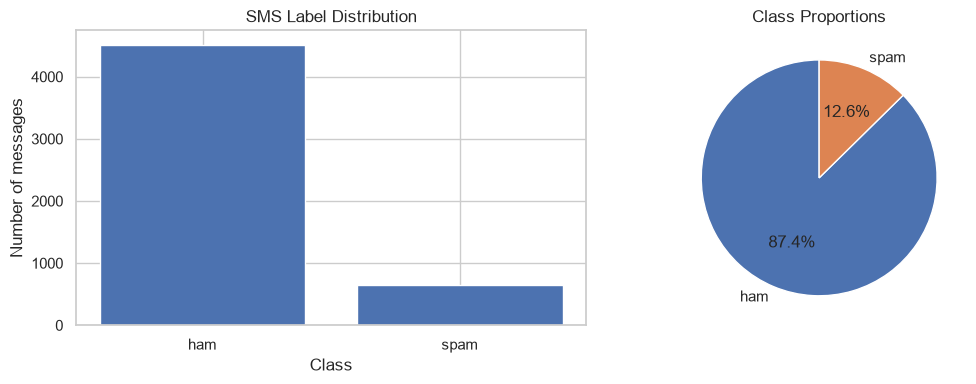

,proportion
label,
ham,0.873719
spam,0.126281


In [4]:
label_counts = df["label"].value_counts().reindex(["ham", "spam"])

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].bar(label_counts.index, label_counts.values)
axes[0].set_title("SMS Label Distribution")
axes[0].set_xlabel("Class")
axes[0].set_ylabel("Number of messages")

axes[1].pie(
    label_counts.values,
    labels=label_counts.index,
    autopct="%1.1f%%",
    startangle=90
)
axes[1].set_title("Class Proportions")
plt.tight_layout()
plt.show()

display((label_counts / label_counts.sum()).rename("proportion").to_frame())


## 5. Explore message lengths

Compare the character lengths of ham and spam messages. This is a simple exploratory view, not a rule used by the classifier.

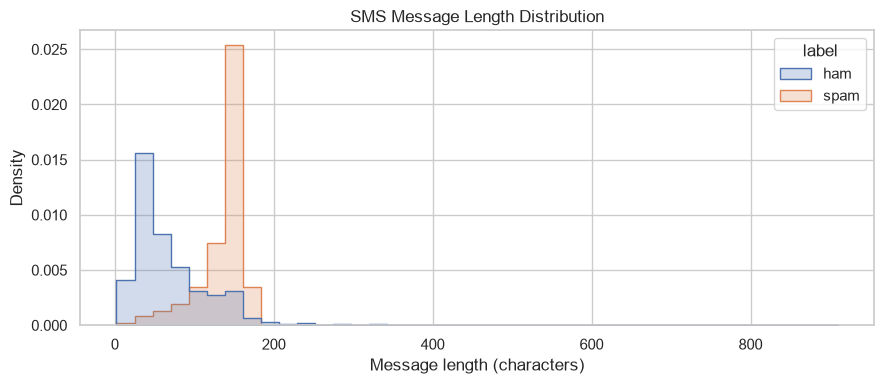

In [5]:
plt.figure(figsize=(9, 4))
sns.histplot(
    data=df,
    x="message_length",
    hue="label",
    bins=40,
    element="step",
    stat="density",
    common_norm=False
)
plt.title("SMS Message Length Distribution")
plt.xlabel("Message length (characters)")
plt.ylabel("Density")
plt.tight_layout()
plt.show()


## 6. Prepare features and stratified train/test split

We use the raw message text as input and the label as the target. The positive class for evaluation is `spam`. Stratification preserves the class ratio in both subsets.

In [6]:
X = df["message"].astype(str)
y = df["label"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training messages:", len(X_train))
print("Testing messages:", len(X_test))
print("\nTraining proportions:")
print(y_train.value_counts(normalize=True).round(3))
print("\nTesting proportions:")
print(y_test.value_counts(normalize=True).round(3))

assert set(X_train).isdisjoint(set(X_test)), "Duplicate messages cross the train/test boundary"


Training messages: 4136
Testing messages: 1035

Training proportions:
label
ham     0.874
spam    0.126
Name: proportion, dtype: float64

Testing proportions:
label
ham     0.873
spam    0.127
Name: proportion, dtype: float64


## 7. Define TF-IDF model pipelines

TF-IDF converts message text into numeric features. It is placed inside each pipeline so the vocabulary and IDF weights are learned from training data only, avoiding test-data leakage.

We compare:
- **Multinomial Naive Bayes:** a common and efficient baseline for word-count/TF-IDF text classification.
- **Logistic Regression:** a linear classifier that learns weights for text features.


In [7]:
def make_tfidf():
    return TfidfVectorizer(
        lowercase=True,
        stop_words="english",
        ngram_range=(1, 2),
        max_features=10000,
        min_df=2,
        sublinear_tf=True
    )

models = {
    "Multinomial Naive Bayes": Pipeline([
        ("tfidf", make_tfidf()),
        ("classifier", MultinomialNB())
    ]),
    "Logistic Regression": Pipeline([
        ("tfidf", make_tfidf()),
        ("classifier", LogisticRegression(
            max_iter=2000,
            class_weight="balanced",
            random_state=RANDOM_STATE
        ))
    ])
}


## 8. Train the models and generate predictions

In [8]:
predictions = {}
spam_probabilities = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    predictions[name] = model.predict(X_test)
    spam_index = list(model.classes_).index("spam")
    spam_probabilities[name] = model.predict_proba(X_test)[:, spam_index]
    print(f"{name}: training complete")



Multinomial Naive Bayes: training complete


Logistic Regression: training complete


## 9. Evaluate precision, recall, and F1-score

Spam is treated as the positive class. Precision answers: of messages predicted as spam, how many were actually spam? Recall answers: of all actual spam messages, how many did the model catch? F1-score balances precision and recall.

In [9]:
def evaluate_model(y_true, y_pred, model_name):
    return {
        "Model": model_name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Spam Precision": precision_score(y_true, y_pred, pos_label="spam", zero_division=0),
        "Spam Recall": recall_score(y_true, y_pred, pos_label="spam", zero_division=0),
        "Spam F1-score": f1_score(y_true, y_pred, pos_label="spam", zero_division=0)
    }

results = pd.DataFrame([
    evaluate_model(y_test, predictions[name], name)
    for name in models
]).set_index("Model")

display(results.round(4))

# Majority-class baseline shows why accuracy alone is misleading.
baseline = DummyClassifier(strategy="most_frequent", random_state=RANDOM_STATE)
baseline.fit(np.zeros((len(y_train), 1)), y_train)
baseline_predictions = baseline.predict(np.zeros((len(y_test), 1)))
baseline_results = pd.DataFrame([evaluate_model(y_test, baseline_predictions, "Always ham baseline")]).set_index("Model")
display(baseline_results.round(4))


,Accuracy,Spam Precision,Spam Recall,Spam F1-score
Model,,,,
Multinomial Naive Bayes,0.9691,1.000,0.7557,0.8609
Logistic Regression,0.9749,0.907,0.8931,0.9000


,Accuracy,Spam Precision,Spam Recall,Spam F1-score
Model,,,,
Always ham baseline,0.8734,0.0,0.0,0.0


## 10. Compare model metrics

The chart focuses on precision, recall, and F1-score for the spam class. Do not select a model based on accuracy alone.

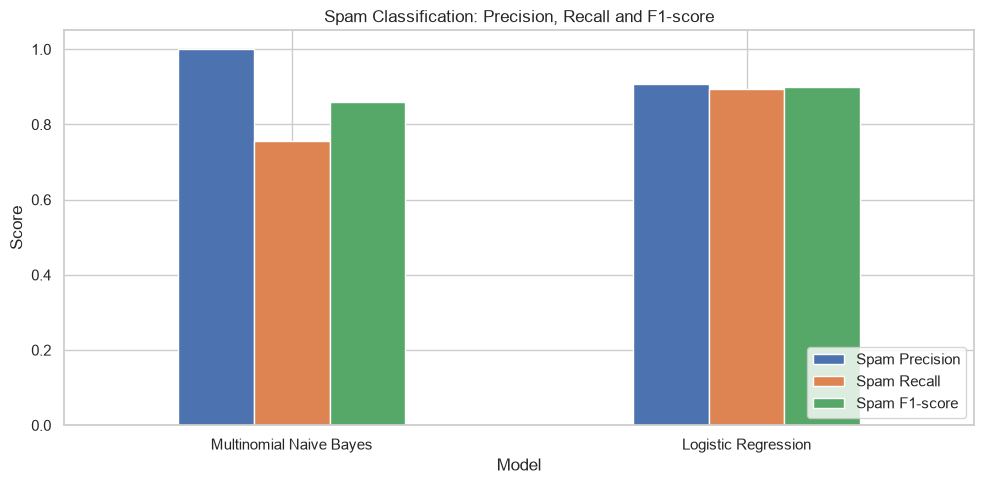

In [10]:
metric_columns = ["Spam Precision", "Spam Recall", "Spam F1-score"]
ax = results[metric_columns].plot(kind="bar", figsize=(10, 5), ylim=(0, 1.05))
ax.set_title("Spam Classification: Precision, Recall and F1-score")
ax.set_ylabel("Score")
ax.set_xlabel("Model")
ax.legend(loc="lower right")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


## 11. Confusion matrices

Rows are actual labels and columns are predicted labels. In spam filtering, false negatives are spam messages incorrectly allowed through as ham; false positives are legitimate messages incorrectly flagged as spam.

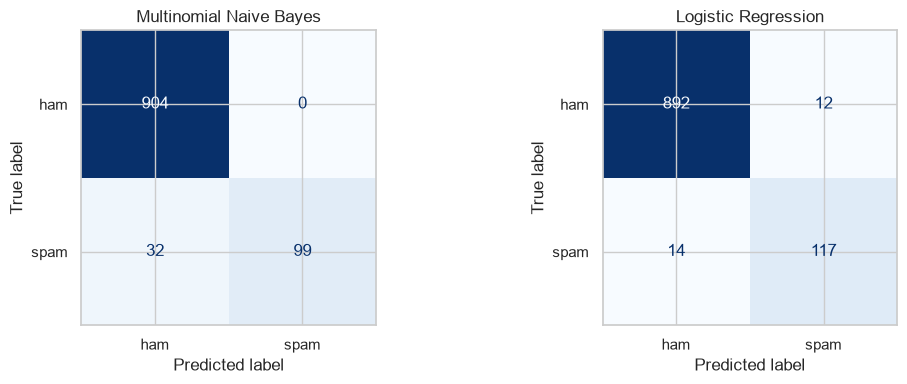

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

for ax, name in zip(axes, models.keys()):
    cm = confusion_matrix(y_test, predictions[name], labels=["ham", "spam"])
    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["ham", "spam"]
    )
    disp.plot(ax=ax, cmap="Blues", colorbar=False, values_format="d")
    ax.set_title(name)

plt.tight_layout()
plt.show()


## 12. Classification reports

Review per-class metrics as well as macro and weighted averages. The spam row is especially important because spam is the minority class.

In [12]:
for name in models:
    print(f"\n{name}")
    print(classification_report(
        y_test,
        predictions[name],
        labels=["ham", "spam"],
        target_names=["ham", "spam"],
        zero_division=0
    ))



Multinomial Naive Bayes
              precision    recall  f1-score   support

         ham       0.97      1.00      0.98       904
        spam       1.00      0.76      0.86       131

    accuracy                           0.97      1035
   macro avg       0.98      0.88      0.92      1035
weighted avg       0.97      0.97      0.97      1035


Logistic Regression
              precision    recall  f1-score   support

         ham       0.98      0.99      0.99       904
        spam       0.91      0.89      0.90       131

    accuracy                           0.97      1035
   macro avg       0.95      0.94      0.94      1035
weighted avg       0.97      0.97      0.97      1035



## 13. Precision-recall curves

Precision-recall curves show the trade-off between precision and recall as the classification threshold changes. Average precision summarizes the curve. This can be useful when the positive class is relatively rare.

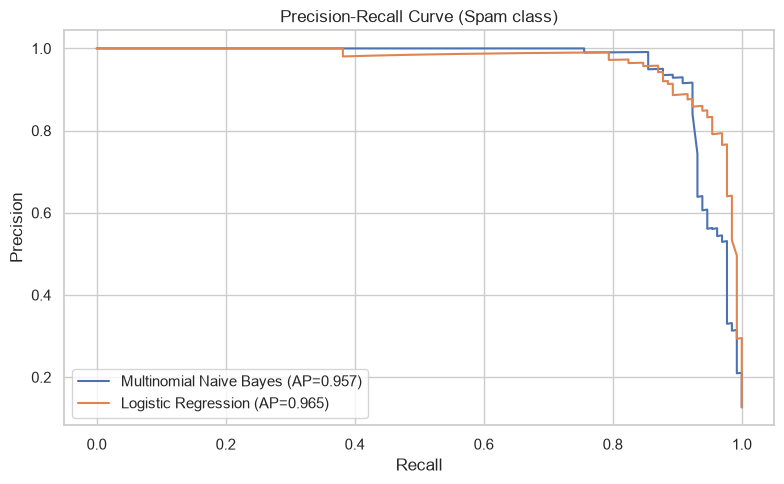

In [13]:
plt.figure(figsize=(8, 5))

for name in models:
    precision, recall, _ = precision_recall_curve(
        y_test,
        spam_probabilities[name],
        pos_label="spam"
    )
    ap = average_precision_score(
        (y_test == "spam").astype(int),
        spam_probabilities[name]
    )
    plt.plot(recall, precision, label=f"{name} (AP={ap:.3f})")

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve (Spam class)")
plt.legend()
plt.tight_layout()
plt.show()


## 14. Inspect informative words

For Logistic Regression, positive coefficients indicate words or phrases associated with the spam class, while negative coefficients indicate association with ham. These are learned associations, not causal explanations.

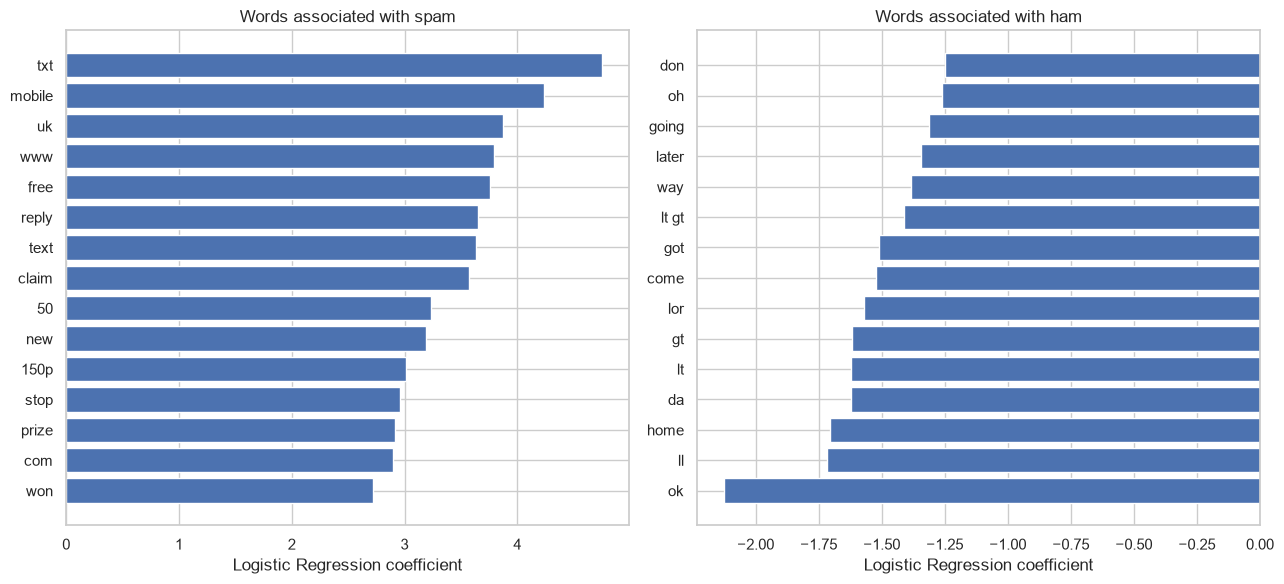

In [14]:
logistic_model = models["Logistic Regression"]
vectorizer = logistic_model.named_steps["tfidf"]
classifier = logistic_model.named_steps["classifier"]

feature_names = np.array(vectorizer.get_feature_names_out())
spam_class_index = list(classifier.classes_).index("spam")
coefficients = classifier.coef_[0]

# Binary Logistic Regression coefficient sign is oriented toward classes_[1].
if spam_class_index == 0:
    coefficients = -coefficients

top_spam_indices = np.argsort(coefficients)[-15:]
top_ham_indices = np.argsort(coefficients)[:15]

fig, axes = plt.subplots(1, 2, figsize=(13, 6))
axes[0].barh(feature_names[top_spam_indices], coefficients[top_spam_indices])
axes[0].set_title("Words associated with spam")
axes[0].set_xlabel("Logistic Regression coefficient")

axes[1].barh(feature_names[top_ham_indices], coefficients[top_ham_indices])
axes[1].set_title("Words associated with ham")
axes[1].set_xlabel("Logistic Regression coefficient")

plt.tight_layout()
plt.show()


## 15. Review a few test predictions

Inspecting examples helps connect numerical evaluation to the actual task. Messages are shown only from the public dataset test split.

In [15]:
review = pd.DataFrame({
    "message": X_test.reset_index(drop=True),
    "actual": y_test.reset_index(drop=True),
    "predicted": pd.Series(predictions["Logistic Regression"])
}).sample(min(10, len(X_test)), random_state=RANDOM_STATE)

display(review)


,message,actual,predicted
294,:-( sad puppy noise,ham,ham
453,Missed call alert. These numbers called but le...,spam,ham
638,"Hi, wlcome back, did wonder if you got eaten b...",ham,ham
139,Pls send me your address sir.,ham,ham
539,URGENT! We are trying to contact you. Last wee...,spam,spam
365,"It‘s reassuring, in this crazy world.",ham,ham
513,Gr8. So how do you handle the victoria island ...,ham,ham
584,"SPJanuary Male Sale! Hot Gay chat now cheaper,...",spam,spam
231,RECPT 1/3. You have ordered a Ringtone. Your o...,spam,spam
210,Nokia phone is lovly..,ham,spam


## 16. Results, conclusion, and limitations

The next cell derives the observations directly from this run. Spam is the positive class.

- **Precision:** among messages flagged as spam, the fraction that really are spam.
- **Recall:** among all spam messages, the fraction the model catches.
- **F1:** the harmonic mean of precision and recall; both must be high for a high F1.
- **False positive:** a legitimate message incorrectly flagged as spam.
- **False negative:** a spam message incorrectly allowed through as ham.

### Limitations
This is one stratified split of a historical English-language corpus. It does not establish performance on current messages, other languages, or new spam campaigns. Exact deduplication does not remove every near-duplicate campaign. No hyperparameter search or threshold optimization is performed. Feature coefficients show learned associations, not causes. Production use would require fresh validation, a review of error costs, monitoring, and privacy safeguards.


In [16]:
winner = results["Spam F1-score"].idxmax()
summary = f"### Observed results\n\nBest spam F1 on this split: **{winner}**.\n\n"
for name, row in results.iterrows():
    cm = confusion_matrix(y_test, predictions[name], labels=["ham", "spam"])
    tn, fp, fn, tp = cm.ravel()
    summary += (f"- **{name}:** accuracy {row['Accuracy']:.2%}, spam precision {row['Spam Precision']:.2%}, "
                f"recall {row['Spam Recall']:.2%}, F1 {row['Spam F1-score']:.4f}. "
                f"Caught {tp} spam; missed {fn}; incorrectly flagged {fp} ham.\n")
summary += (f"\nThe always-ham baseline reaches {baseline_results.iloc[0]['Accuracy']:.2%} accuracy "
            "with zero spam recall and F1. This shows why accuracy alone is insufficient. "
            "These results describe this held-out split; they do not guarantee future performance.")
display(Markdown(summary))


### Observed results

Best spam F1 on this split: **Logistic Regression**.

- **Multinomial Naive Bayes:** accuracy 96.91%, spam precision 100.00%, recall 75.57%, F1 0.8609. Caught 99 spam; missed 32; incorrectly flagged 0 ham.
- **Logistic Regression:** accuracy 97.49%, spam precision 90.70%, recall 89.31%, F1 0.9000. Caught 117 spam; missed 14; incorrectly flagged 12 ham.

The always-ham baseline reaches 87.34% accuracy with zero spam recall and F1. This shows why accuracy alone is insufficient. These results describe this held-out split; they do not guarantee future performance.

## 17. Reproducibility and final check

Run this cell after executing the notebook from top to bottom.

In [17]:
print("Experiment configuration")
print("------------------------")
print("Dataset: UCI SMS Spam Collection")
print("Train/test split: 80/20, stratified")
print("Random state:", RANDOM_STATE)
print("Positive class: spam")
print("Models:", ", ".join(models.keys()))
print("\nFinal metrics:")
display(results.round(4))
print("\nNotebook run completed.")


Experiment configuration
------------------------
Dataset: UCI SMS Spam Collection
Train/test split: 80/20, stratified
Random state: 42
Positive class: spam
Models: Multinomial Naive Bayes, Logistic Regression

Final metrics:


,Accuracy,Spam Precision,Spam Recall,Spam F1-score
Model,,,,
Multinomial Naive Bayes,0.9691,1.000,0.7557,0.8609
Logistic Regression,0.9749,0.907,0.8931,0.9000



Notebook run completed.


In [18]:
print("Python:", platform.python_version())
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Scikit-learn:", sklearn.__version__)
assert results.shape == (2, 4)
assert np.isfinite(results.to_numpy()).all()
assert all(len(predictions[name]) == len(y_test) for name in models)
print("Verification passed: both pipelines produced finite metrics and complete test predictions.")


Python: 3.12.14
NumPy: 2.5.4
Pandas: 3.1.1
Scikit-learn: 1.9.1
Verification passed: both pipelines produced finite metrics and complete test predictions.
